# IoT Sensor Anomaly Detection

Complete end-to-end ML solution for detecting anomalies in time series sensor data.

**Models**: Isolation Forest + LSTM Autoencoder  
**Data**: 4 sensors, 10,000 samples  
**Output**: Trained models + 17+ visualizations

## 1. Setup and Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sys
import os
warnings.filterwarnings('ignore')
np.random.seed(42)

# Add project root to path
sys.path.insert(0, os.path.abspath('..'))

# Import modules
import config
from src.data_generator import SensorDataGenerator
from src.data_preprocessing import DataPreprocessor, FeatureEngineer
from src.eda_visualization import EDAVisualizer
from src.model_isolation_forest import IsolationForestDetector
from src.model_lstm_autoencoder import LSTMAutoencoder
from src.model_evaluation import ModelEvaluator, ModelComparator
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-darkgrid')
print("✓ All imports successful!")

✓ All imports successful!


## 2. Generate Synthetic Sensor Data

In [2]:
generator = SensorDataGenerator(num_samples=config.NUM_SAMPLES)
df = generator.generate_dataset()
generator.save_dataset(df)  # Pass df as argument

print(f"Data shape: {df.shape}")
print(f"Anomalies: {df['anomaly'].sum()} ({df['anomaly'].mean()*100:.1f}%)")
df.head()

2025-10-23 14:15:14,023 - INFO - Initialized SensorDataGenerator with 10000 samples
2025-10-23 14:15:14,024 - INFO - Generating synthetic sensor dataset...
2025-10-23 14:15:14,034 - INFO - Generating temperature data...
2025-10-23 14:15:14,037 - INFO - Injected 997 anomalies (9.97%)
2025-10-23 14:15:14,038 - INFO - Generating vibration data...
2025-10-23 14:15:14,040 - INFO - Injected 749 anomalies (7.49%)
2025-10-23 14:15:14,040 - INFO - Generating pressure data...
2025-10-23 14:15:14,042 - INFO - Injected 894 anomalies (8.94%)
2025-10-23 14:15:14,043 - INFO - Generating rotation_speed data...
2025-10-23 14:15:14,045 - INFO - Injected 809 anomalies (8.09%)
2025-10-23 14:15:14,047 - INFO - Dataset generated with shape: (10000, 5)
2025-10-23 14:15:14,047 - INFO - Total anomalies: 2947 (29.47%)
2025-10-23 14:15:14,048 - INFO - Missing values: 800
2025-10-23 14:15:14,108 - INFO - Dataset saved to /Users/deeptanush.kapaka/Documents/project/data/sensor_data.csv


Data shape: (10000, 5)
Anomalies: 2947 (29.5%)


,temperature,vibration,pressure,rotation_speed,anomaly
timestamp,,,,,
2024-01-01 00:00:00,77.483571,0.544962,105.244738,1548.641555,0
2024-01-01 00:01:00,74.734135,0.937449,95.265731,1618.092757,1
2024-01-01 00:02:00,79.085061,0.400869,101.370656,1451.270765,0
2024-01-01 00:03:00,83.874385,0.498242,103.487527,1577.844636,1
2024-01-01 00:04:00,75.488389,0.536696,104.582484,1509.207141,0


## 3. Exploratory Data Analysis

2025-10-23 14:15:19,415 - INFO - Initialized EDAVisualizer with 4 sensors
2025-10-23 14:15:19,415 - INFO - Creating time series plot...
2025-10-23 14:15:20,472 - INFO - Time series plot saved to /Users/deeptanush.kapaka/Documents/project/results/plots/01_time_series.png


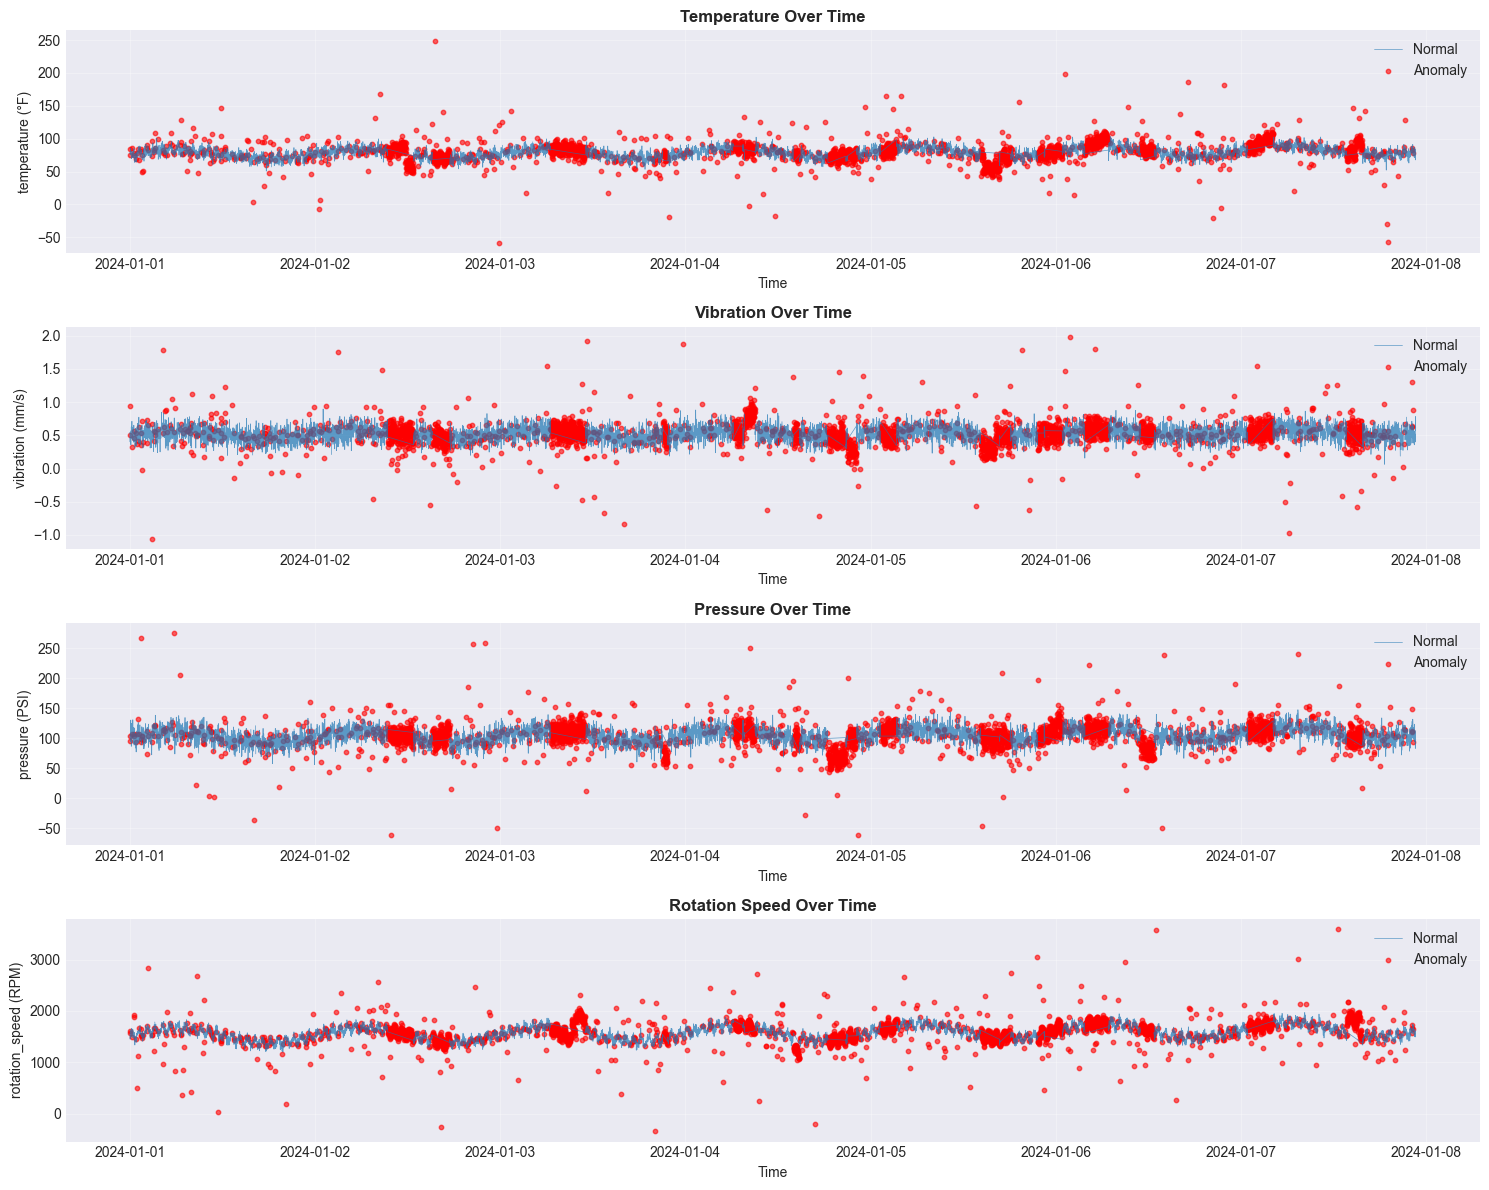

2025-10-23 14:15:20,638 - INFO - Creating distribution plots...
2025-10-23 14:15:21,225 - INFO - Distribution plots saved to /Users/deeptanush.kapaka/Documents/project/results/plots/02_distributions.png


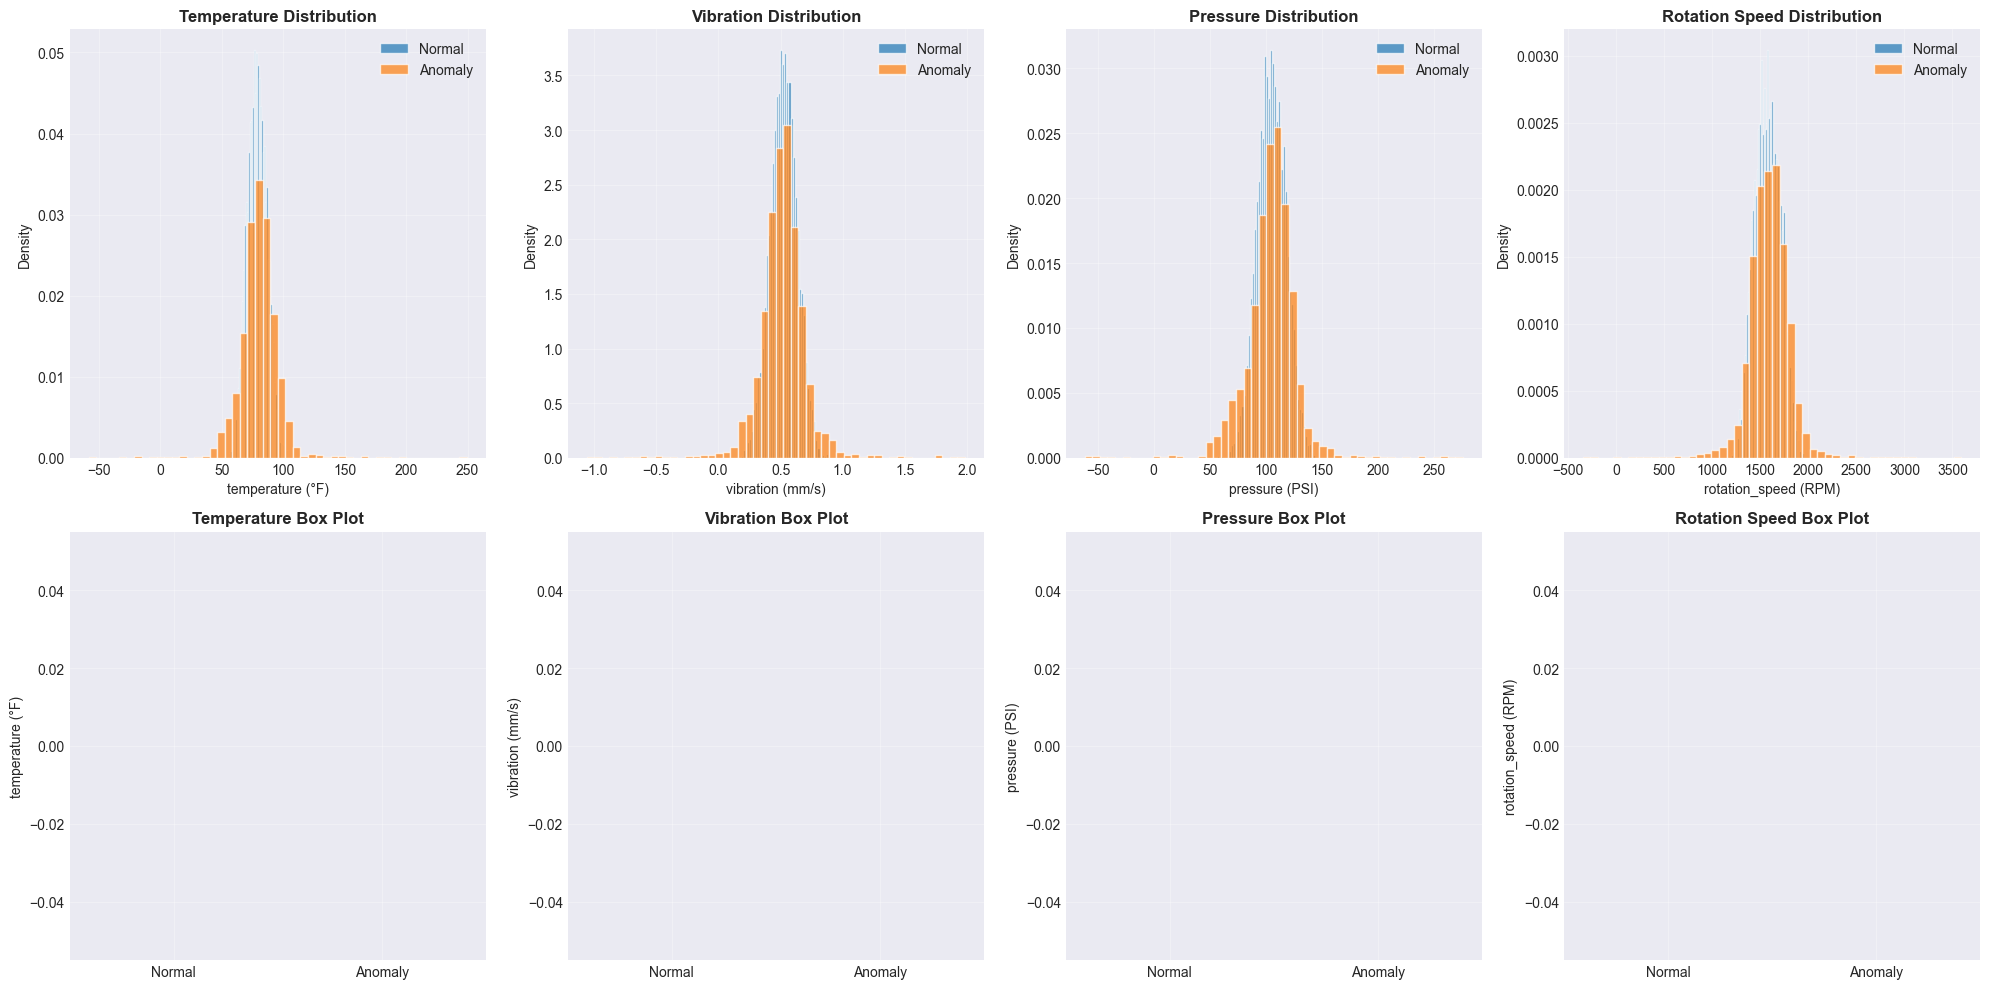

2025-10-23 14:15:21,418 - INFO - Creating correlation matrix...
2025-10-23 14:15:21,618 - INFO - Correlation matrix saved to /Users/deeptanush.kapaka/Documents/project/results/plots/03_correlation_matrix.png


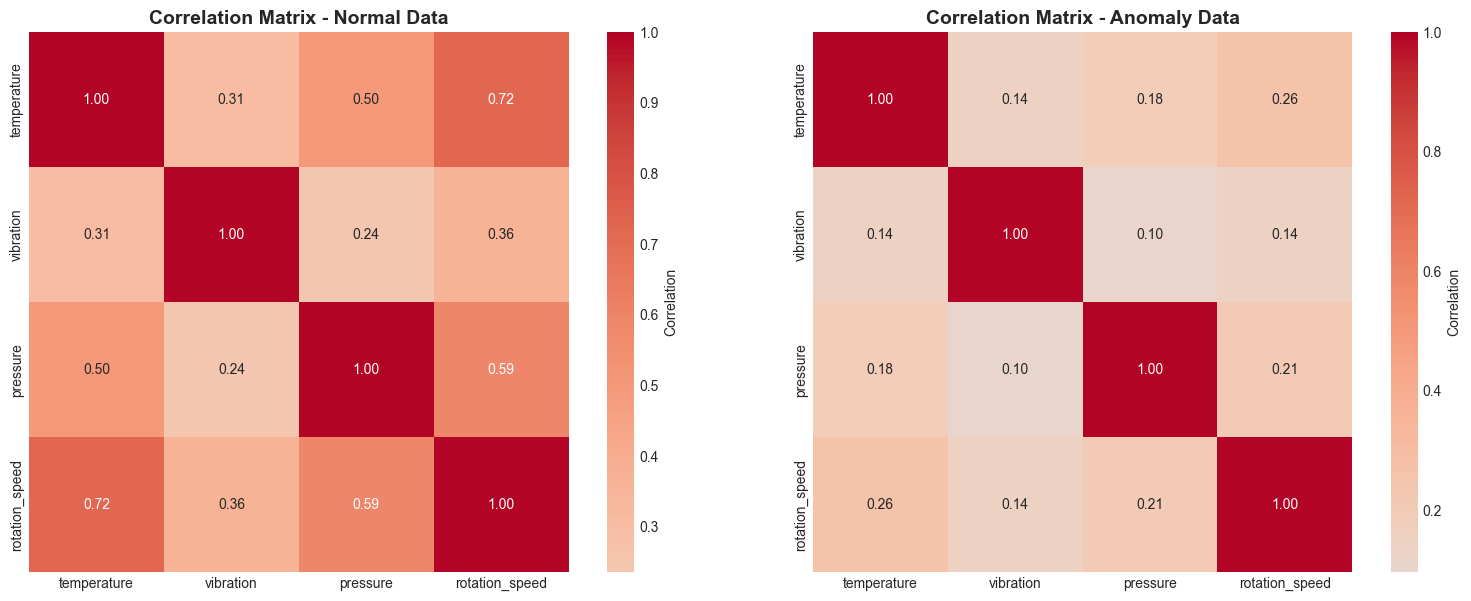

2025-10-23 14:15:21,670 - INFO - Creating statistical summary...
2025-10-23 14:15:22,038 - INFO - Statistical summary saved to /Users/deeptanush.kapaka/Documents/project/results/plots/04_statistical_summary.png


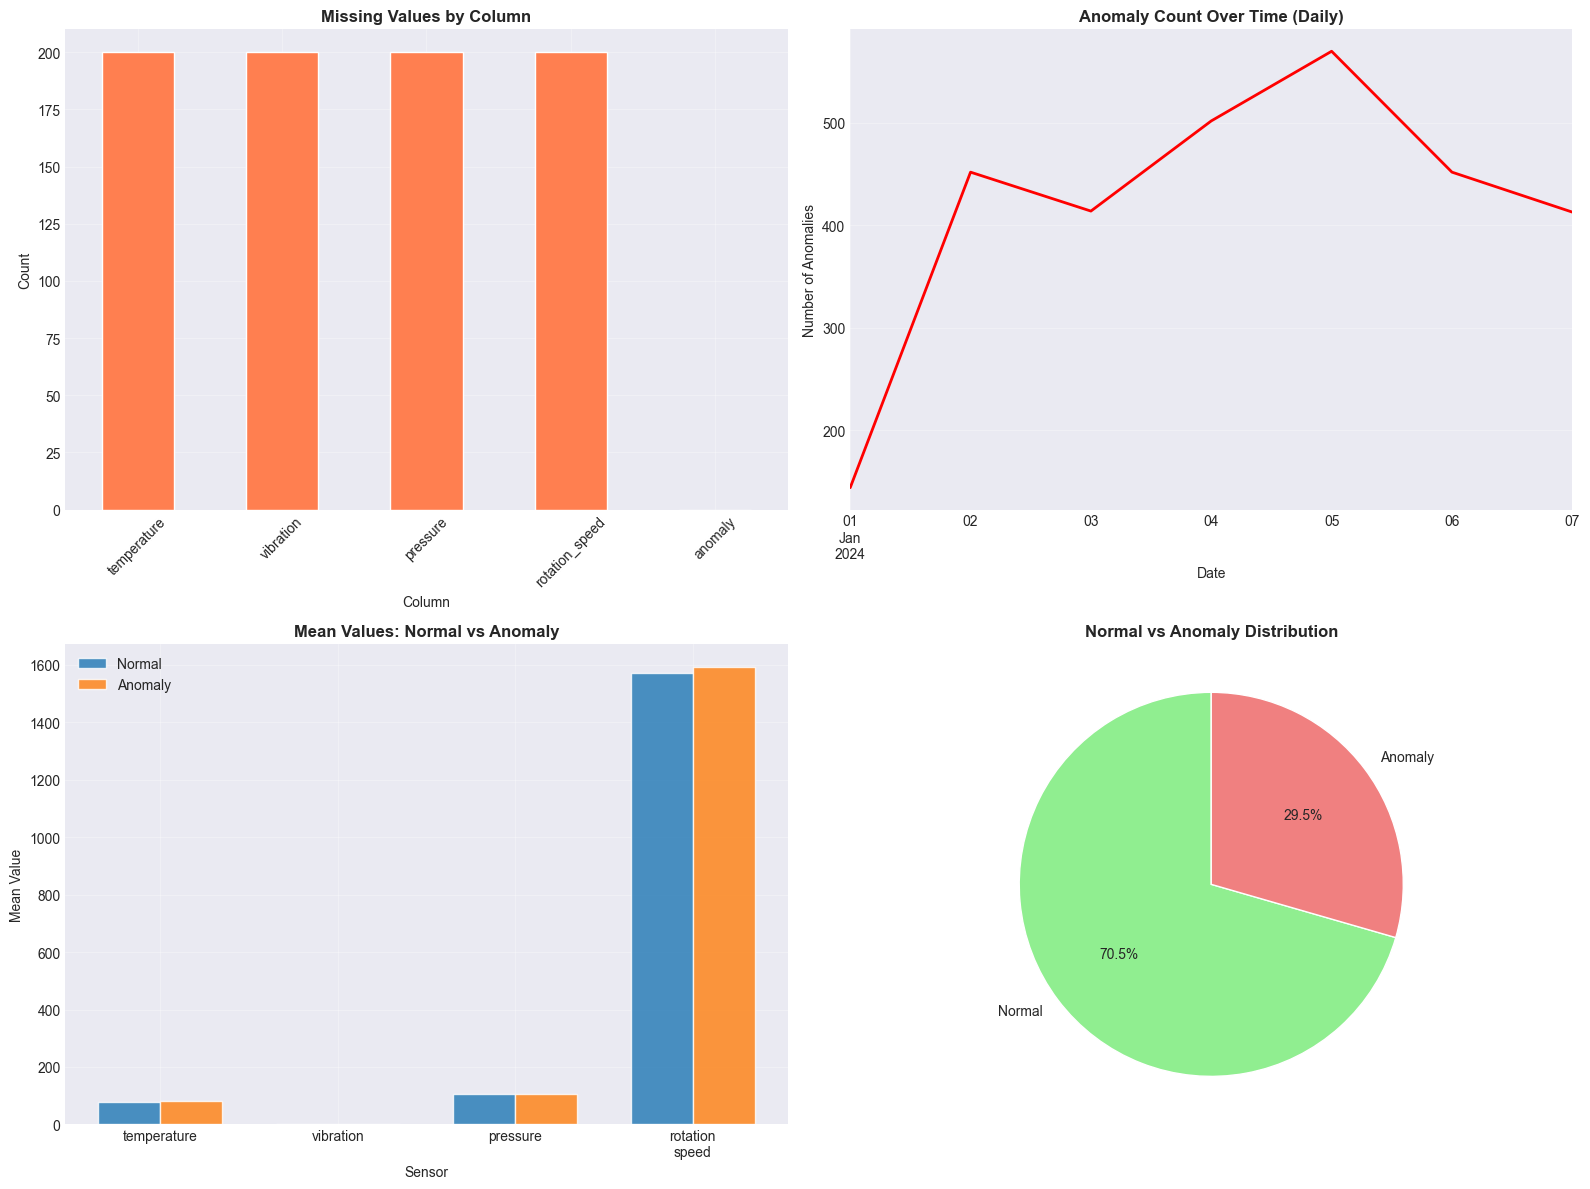

✓ EDA complete! Check results/plots/ folder


In [3]:
visualizer = EDAVisualizer(df)
visualizer.plot_time_series(save_path=f"{config.PLOTS_DIR}/01_time_series.png")
visualizer.plot_distributions(save_path=f"{config.PLOTS_DIR}/02_distributions.png")
visualizer.plot_correlation_matrix(save_path=f"{config.PLOTS_DIR}/03_correlation_matrix.png")
visualizer.plot_statistical_summary(save_path=f"{config.PLOTS_DIR}/04_statistical_summary.png")
print("✓ EDA complete! Check results/plots/ folder")

## 4. Data Preprocessing

In [4]:
preprocessor = DataPreprocessor()
df_clean = preprocessor.handle_missing_values(df)
print(f"Missing values after preprocessing: {df_clean.isnull().sum().sum()}")

2025-10-23 14:15:27,674 - INFO - Initialized DataPreprocessor
2025-10-23 14:15:27,674 - INFO - Handling missing values...
2025-10-23 14:15:27,678 - INFO - Missing values after imputation: 0


Missing values after preprocessing: 0


## 5. Feature Engineering

In [5]:
engineer = FeatureEngineer()
df_features = engineer.create_all_features(df_clean)
X_scaled, feature_names = engineer.scale_features(df_features, fit=True)
y = df_features['anomaly'].values
engineer.save_scaler()

print(f"Original features: 4")
print(f"Engineered features: {len(feature_names)}")
print(f"Shape: {X_scaled.shape}")

2025-10-23 14:15:30,905 - INFO - Initialized FeatureEngineer
2025-10-23 14:15:30,906 - INFO - Creating all features...
2025-10-23 14:15:30,907 - INFO - Creating rolling window features...
2025-10-23 14:15:30,951 - INFO - Created rolling features. New shape: (10000, 69)
2025-10-23 14:15:30,952 - INFO - Creating lag features...
2025-10-23 14:15:30,972 - INFO - Created lag features. New shape: (10000, 81)
2025-10-23 14:15:30,973 - INFO - Creating difference features...
2025-10-23 14:15:30,979 - INFO - Created difference features. New shape: (10000, 93)
2025-10-23 14:15:30,980 - INFO - Creating statistical features...
2025-10-23 14:15:31,011 - INFO - Created statistical features. New shape: (10000, 109)
2025-10-23 14:15:31,012 - INFO - Creating interaction features...
2025-10-23 14:15:31,018 - INFO - Created interaction features. New shape: (10000, 117)
2025-10-23 14:15:31,025 - INFO - Feature engineering complete. Final shape: (10000, 117)
2025-10-23 14:15:31,026 - INFO - Total features c

Original features: 4
Engineered features: 116
Shape: (10000, 116)


## 6. Train-Test Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=config.TEST_SIZE, 
    random_state=config.RANDOM_SEED, stratify=y
)

timestamps_train, timestamps_test = train_test_split(
    df_features.index, test_size=config.TEST_SIZE,
    random_state=config.RANDOM_SEED, stratify=y
)

print(f"Training: {X_train.shape[0]} samples ({y_train.mean()*100:.1f}% anomalies)")
print(f"Testing: {X_test.shape[0]} samples ({y_test.mean()*100:.1f}% anomalies)")

Training: 7000 samples (29.5% anomalies)
Testing: 3000 samples (29.5% anomalies)


## 7. Train Isolation Forest

**Algorithm**: Ensemble of decision trees that isolate anomalies  
**Speed**: Very fast (<1ms per prediction)  
**Best for**: Real-time monitoring

In [7]:
if_detector = IsolationForestDetector(
    contamination=config.ISOLATION_FOREST_PARAMS['contamination'],
    n_estimators=config.ISOLATION_FOREST_PARAMS['n_estimators']
)
if_detector.fit(X_train)
y_pred_if = if_detector.predict(X_test)
y_scores_if = if_detector.predict_proba(X_test)
if_detector.save_model()

print(f"✓ Isolation Forest trained")
print(f"Predicted anomalies: {y_pred_if.sum()} ({y_pred_if.mean()*100:.1f}%)")

2025-10-23 14:15:46,035 - INFO - Initialized IsolationForest with contamination=0.05, n_estimators=100
2025-10-23 14:15:46,035 - INFO - Training Isolation Forest on data with shape (7000, 116)...
2025-10-23 14:15:46,149 - INFO - Training complete. Anomaly score threshold: 0.4693
2025-10-23 14:15:46,176 - INFO - Model saved to /Users/deeptanush.kapaka/Documents/project/models/isolation_forest_model.pkl


✓ Isolation Forest trained
Predicted anomalies: 141 (4.7%)


## 8. Train LSTM Autoencoder

**Algorithm**: Deep learning model that learns to reconstruct normal patterns  
**Speed**: Slower (~100ms per prediction)  
**Best for**: Batch analysis, complex patterns

*Note: This will take 5-10 minutes to train*

In [8]:
lstm_ae = LSTMAutoencoder(
    sequence_length=config.LSTM_PARAMS['sequence_length'],
    encoding_dim=config.LSTM_PARAMS['encoding_dim'],
    lstm_units=config.LSTM_PARAMS['lstm_units']
)
lstm_ae.fit(X_train, y_train, 
            epochs=config.LSTM_PARAMS['epochs'],
            batch_size=config.LSTM_PARAMS['batch_size'])
y_pred_lstm = lstm_ae.predict(X_test)
y_scores_lstm = lstm_ae.predict_proba(X_test)
lstm_ae.save_model()

print(f"✓ LSTM Autoencoder trained")
print(f"Predicted anomalies: {y_pred_lstm.sum()} ({y_pred_lstm.mean()*100:.1f}%)")

2025-10-23 14:15:52,603 - INFO - Initialized LSTMAutoencoder with sequence_length=60, encoding_dim=32, lstm_units=[64, 32]
2025-10-23 14:15:52,603 - INFO - Preparing sequences from data with shape (7000, 116)...
2025-10-23 14:15:52,689 - INFO - Model architecture built
2025-10-23 14:15:52,690 - INFO - Total parameters: 100,500
2025-10-23 14:15:52,732 - INFO - Created 6941 sequences with shape (6941, 60, 116)
2025-10-23 14:15:52,732 - INFO - Training model for 50 epochs...


Epoch 1/50
174/174 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - loss: 2.3121 - mae: 0.7361 - val_loss: 2.6810 - val_mae: 0.7507 - learning_rate: 0.0010
Epoch 2/50
174/174 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - loss: 2.2996 - mae: 0.7385 - val_loss: 2.6792 - val_mae: 0.7549 - learning_rate: 0.0010
Epoch 3/50
174/174 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - loss: 2.2951 - mae: 0.7394 - val_loss: 2.6783 - val_mae: 0.7543 - learning_rate: 0.0010
Epoch 4/50
174/174 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - loss: 2.2923 - mae: 0.7396 - val_loss: 2.6786 - val_mae: 0.7529 - learning_rate: 0.0010
Epoch 5/50
174/174 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - loss: 2.2887 - mae: 0.7399 - val_loss: 2.6785 - val_mae: 0.7528 - learning_rate: 0.0010
Epoch 6/50
174/174 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - loss: 2.2860 - mae: 0.7401 - val_loss: 2.6798 - val_mae: 0.7531 - learning_rate: 0.0010
Epoch 7/50
174/174 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - loss: 2.2842 - mae: 0.7404 - val_loss: 2.6779 - val_mae: 0.7523 - learning_rate: 0.001

2025-10-23 14:18:16,556 - INFO - Calculating anomaly threshold...
2025-10-23 14:18:19,392 - INFO - Training complete. Threshold set to 0.800114
2025-10-23 14:18:21,208 - INFO - Model saved to /Users/deeptanush.kapaka/Documents/project/models/lstm_autoencoder_model.keras


✓ LSTM Autoencoder trained
Predicted anomalies: 58 (1.9%)


2025-10-23 14:18:32,786 - INFO - Training history plot saved to /Users/deeptanush.kapaka/Documents/project/results/plots/06_lstm_training.png


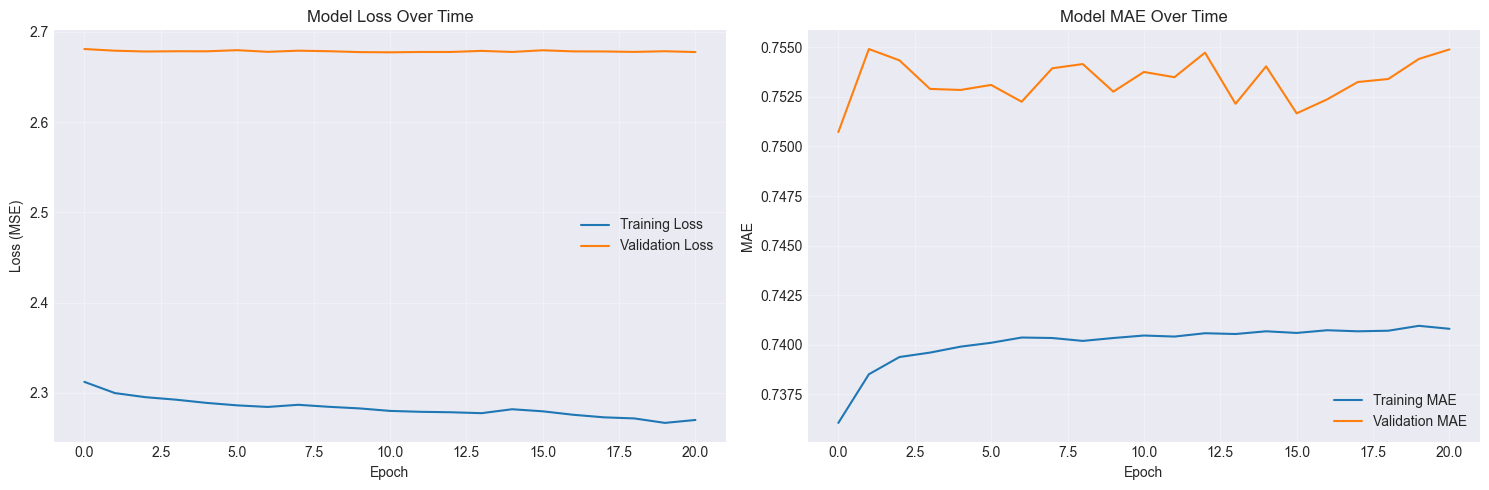

2025-10-23 14:18:33,200 - INFO - Reconstruction examples saved to /Users/deeptanush.kapaka/Documents/project/results/plots/07_lstm_reconstruction.png


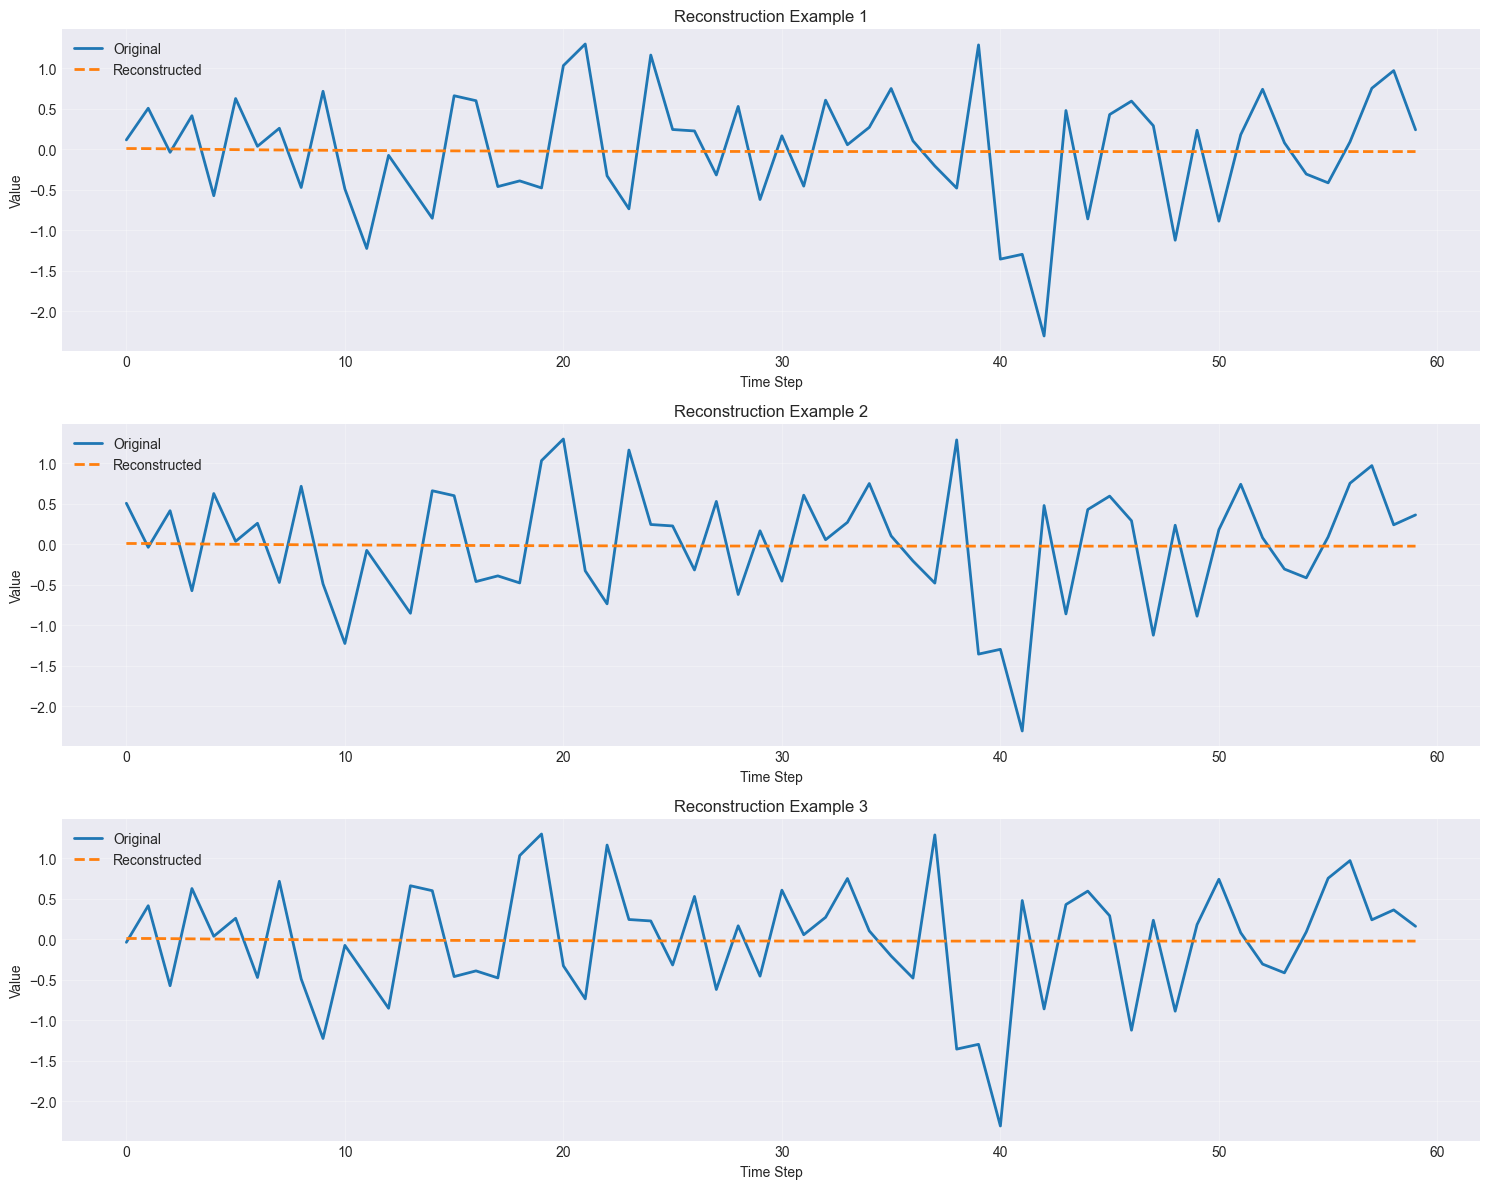

In [9]:
# Visualize training
lstm_ae.plot_training_history(save_path=f"{config.PLOTS_DIR}/06_lstm_training.png")
lstm_ae.plot_reconstruction_examples(X_test, n_examples=3, 
                                     save_path=f"{config.PLOTS_DIR}/07_lstm_reconstruction.png")

## 9. Evaluate Isolation Forest

In [10]:
evaluator_if = ModelEvaluator("Isolation Forest")
metrics_if = evaluator_if.calculate_metrics(y_test, y_pred_if, y_scores_if)
evaluator_if.save_metrics()

print("Isolation Forest Metrics:")
print(f"  Accuracy:  {metrics_if['accuracy']:.4f}")
print(f"  Precision: {metrics_if['precision']:.4f}")
print(f"  Recall:    {metrics_if['recall']:.4f}")
print(f"  F1-Score:  {metrics_if['f1_score']:.4f}")
if metrics_if.get('roc_auc'):
    print(f"  ROC-AUC:   {metrics_if['roc_auc']:.4f}")

2025-10-23 14:18:53,144 - INFO - Initialized ModelEvaluator for Isolation Forest
2025-10-23 14:18:53,144 - INFO - Calculating metrics for Isolation Forest...
2025-10-23 14:18:53,152 - INFO - Metrics calculated: {'accuracy': 0.729, 'precision': 0.75177304964539, 'recall': 0.11990950226244344, 'f1_score': 0.20682926829268292, 'confusion_matrix': [[2081, 35], [778, 106]], 'true_negatives': 2081, 'false_positives': 35, 'false_negatives': 778, 'true_positives': 106, 'specificity': np.float64(0.9834593572778828), 'false_positive_rate': np.float64(0.0165406427221172), 'roc_auc': 0.7038968342899178, 'pr_auc': 0.5208759789893688}
2025-10-23 14:18:53,153 - INFO - Metrics saved to /Users/deeptanush.kapaka/Documents/project/results/isolation_forest_metrics.json


Isolation Forest Metrics:
  Accuracy:  0.7290
  Precision: 0.7518
  Recall:    0.1199
  F1-Score:  0.2068
  ROC-AUC:   0.7039


2025-10-23 14:18:56,704 - INFO - Confusion matrix saved to /Users/deeptanush.kapaka/Documents/project/results/plots/08_if_cm.png


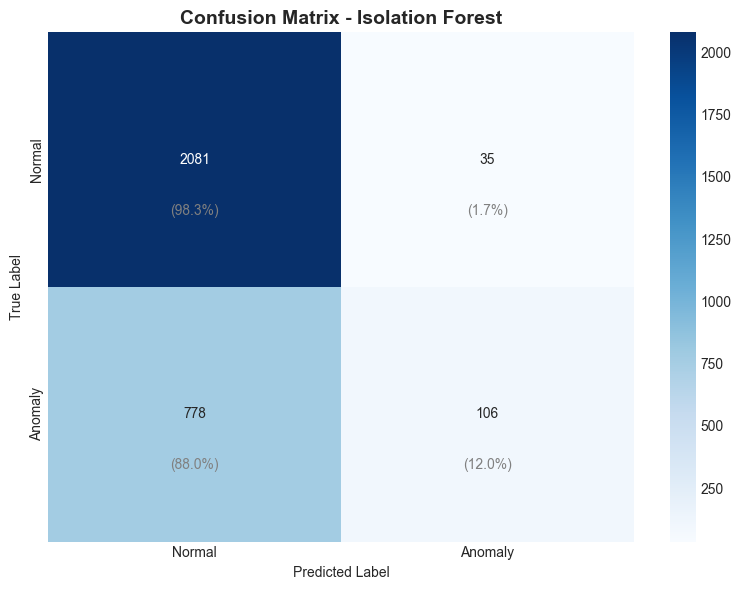

2025-10-23 14:18:56,942 - INFO - ROC curve saved to /Users/deeptanush.kapaka/Documents/project/results/plots/09_if_roc.png


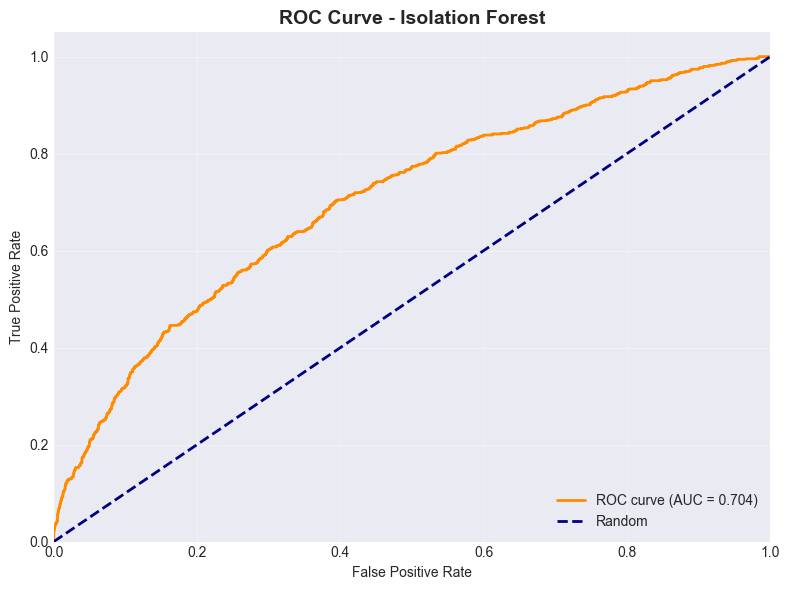

2025-10-23 14:18:57,056 - INFO - Precision-Recall curve saved to /Users/deeptanush.kapaka/Documents/project/results/plots/10_if_pr.png


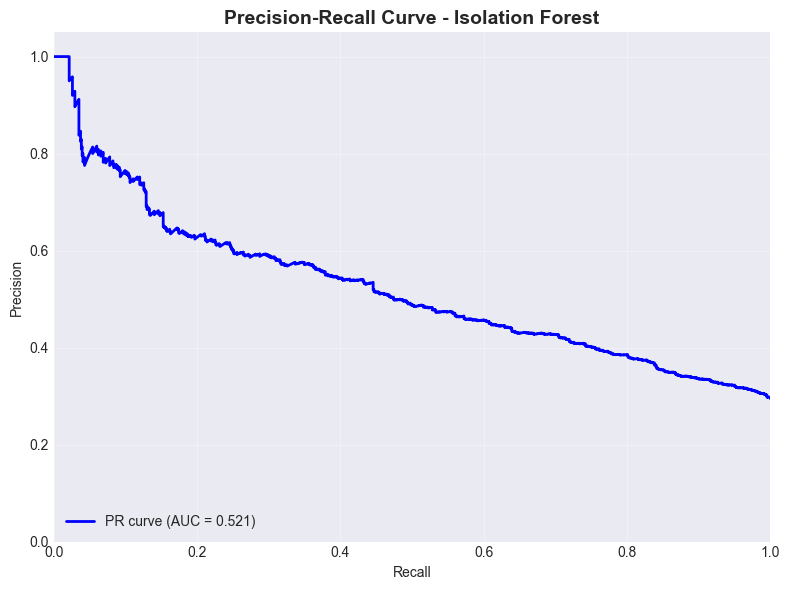

In [11]:
# Visualizations
evaluator_if.plot_confusion_matrix(y_test, y_pred_if, 
                                   save_path=f"{config.PLOTS_DIR}/08_if_cm.png")
evaluator_if.plot_roc_curve(y_test, y_scores_if, 
                            save_path=f"{config.PLOTS_DIR}/09_if_roc.png")
evaluator_if.plot_precision_recall_curve(y_test, y_scores_if,
                                        save_path=f"{config.PLOTS_DIR}/10_if_pr.png")

## 10. Evaluate LSTM Autoencoder

In [12]:
evaluator_lstm = ModelEvaluator("LSTM Autoencoder")
metrics_lstm = evaluator_lstm.calculate_metrics(y_test, y_pred_lstm, y_scores_lstm)
evaluator_lstm.save_metrics()

print("LSTM Autoencoder Metrics:")
print(f"  Accuracy:  {metrics_lstm['accuracy']:.4f}")
print(f"  Precision: {metrics_lstm['precision']:.4f}")
print(f"  Recall:    {metrics_lstm['recall']:.4f}")
print(f"  F1-Score:  {metrics_lstm['f1_score']:.4f}")
if metrics_lstm.get('roc_auc'):
    print(f"  ROC-AUC:   {metrics_lstm['roc_auc']:.4f}")

2025-10-23 14:19:03,696 - INFO - Initialized ModelEvaluator for LSTM Autoencoder
2025-10-23 14:19:03,697 - INFO - Calculating metrics for LSTM Autoencoder...
2025-10-23 14:19:03,703 - INFO - Metrics calculated: {'accuracy': 0.6993333333333334, 'precision': 0.3448275862068966, 'recall': 0.02262443438914027, 'f1_score': 0.04246284501061571, 'confusion_matrix': [[2078, 38], [864, 20]], 'true_negatives': 2078, 'false_positives': 38, 'false_negatives': 864, 'true_positives': 20, 'specificity': np.float64(0.9820415879017014), 'false_positive_rate': np.float64(0.017958412098298678), 'roc_auc': 0.5200936198239657, 'pr_auc': 0.3121885716687114}
2025-10-23 14:19:03,704 - INFO - Metrics saved to /Users/deeptanush.kapaka/Documents/project/results/lstm_autoencoder_metrics.json


LSTM Autoencoder Metrics:
  Accuracy:  0.6993
  Precision: 0.3448
  Recall:    0.0226
  F1-Score:  0.0425
  ROC-AUC:   0.5201


2025-10-23 14:19:06,100 - INFO - Confusion matrix saved to /Users/deeptanush.kapaka/Documents/project/results/plots/11_lstm_cm.png


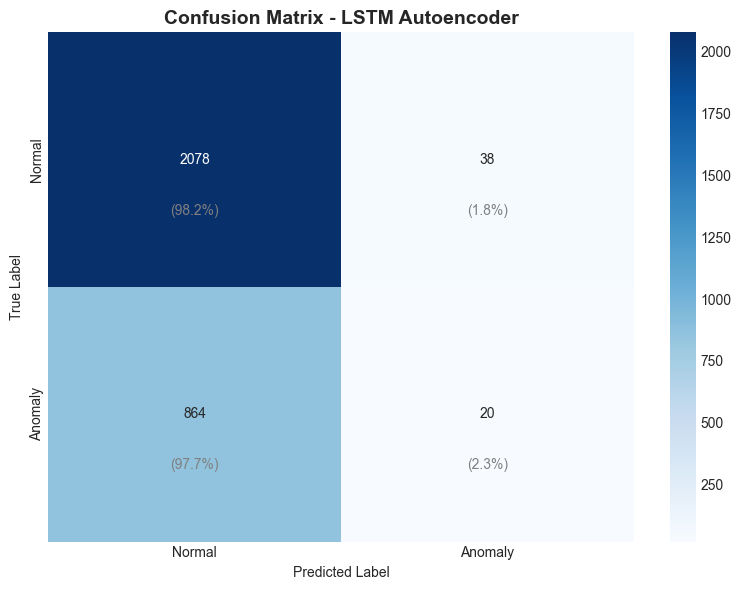

2025-10-23 14:19:06,219 - INFO - ROC curve saved to /Users/deeptanush.kapaka/Documents/project/results/plots/12_lstm_roc.png


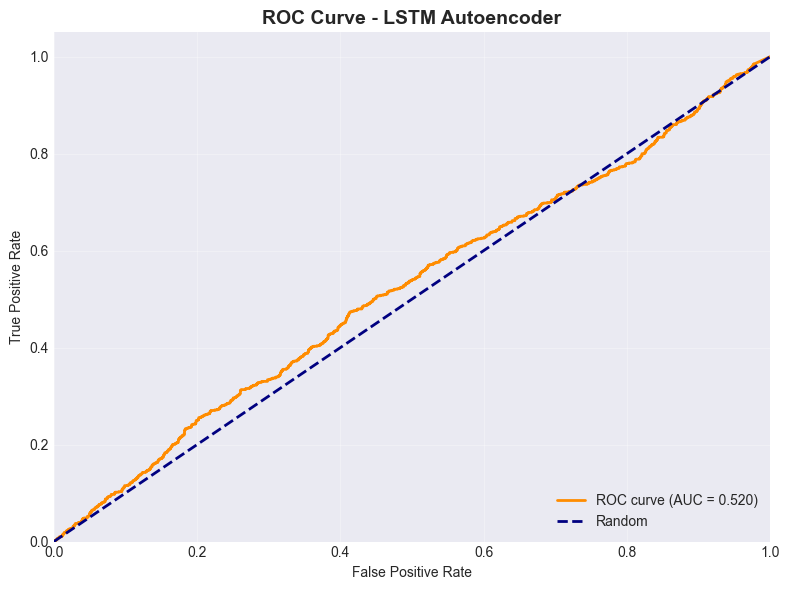

2025-10-23 14:19:06,322 - INFO - Precision-Recall curve saved to /Users/deeptanush.kapaka/Documents/project/results/plots/13_lstm_pr.png


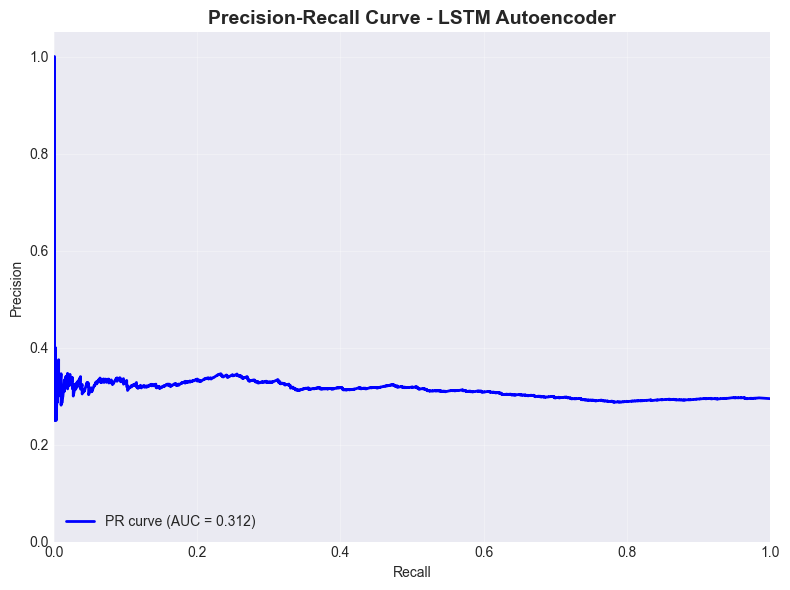

In [13]:
# Visualizations
evaluator_lstm.plot_confusion_matrix(y_test, y_pred_lstm,
                                    save_path=f"{config.PLOTS_DIR}/11_lstm_cm.png")
evaluator_lstm.plot_roc_curve(y_test, y_scores_lstm,
                              save_path=f"{config.PLOTS_DIR}/12_lstm_roc.png")
evaluator_lstm.plot_precision_recall_curve(y_test, y_scores_lstm,
                                          save_path=f"{config.PLOTS_DIR}/13_lstm_pr.png")

## 11. Anomaly Detection Timeline

2025-10-23 14:19:10,952 - INFO - Anomaly timeline saved to /Users/deeptanush.kapaka/Documents/project/results/plots/14_if_timeline.png


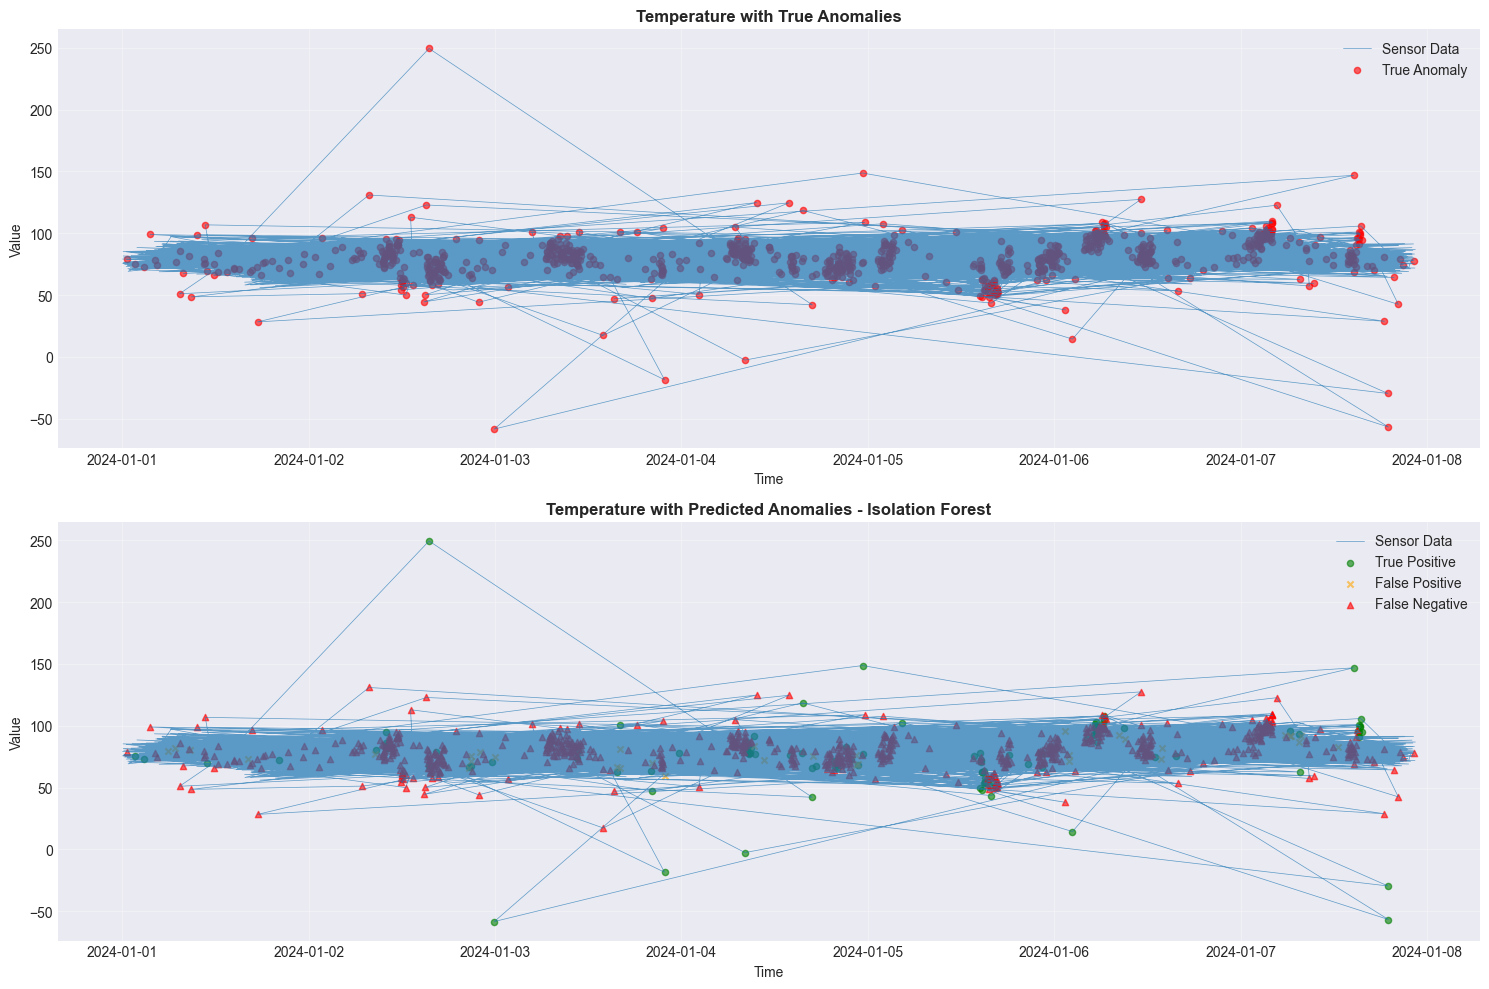

In [14]:
# Get sensor data for visualization
temp_test = df_features.loc[timestamps_test, 'temperature'].values

# Isolation Forest timeline
evaluator_if.plot_anomaly_timeline(
    timestamps_test, y_test, y_pred_if,
    sensor_data=temp_test, sensor_name='Temperature',
    save_path=f"{config.PLOTS_DIR}/14_if_timeline.png"
)

2025-10-23 14:19:19,620 - INFO - Anomaly timeline saved to /Users/deeptanush.kapaka/Documents/project/results/plots/15_lstm_timeline.png


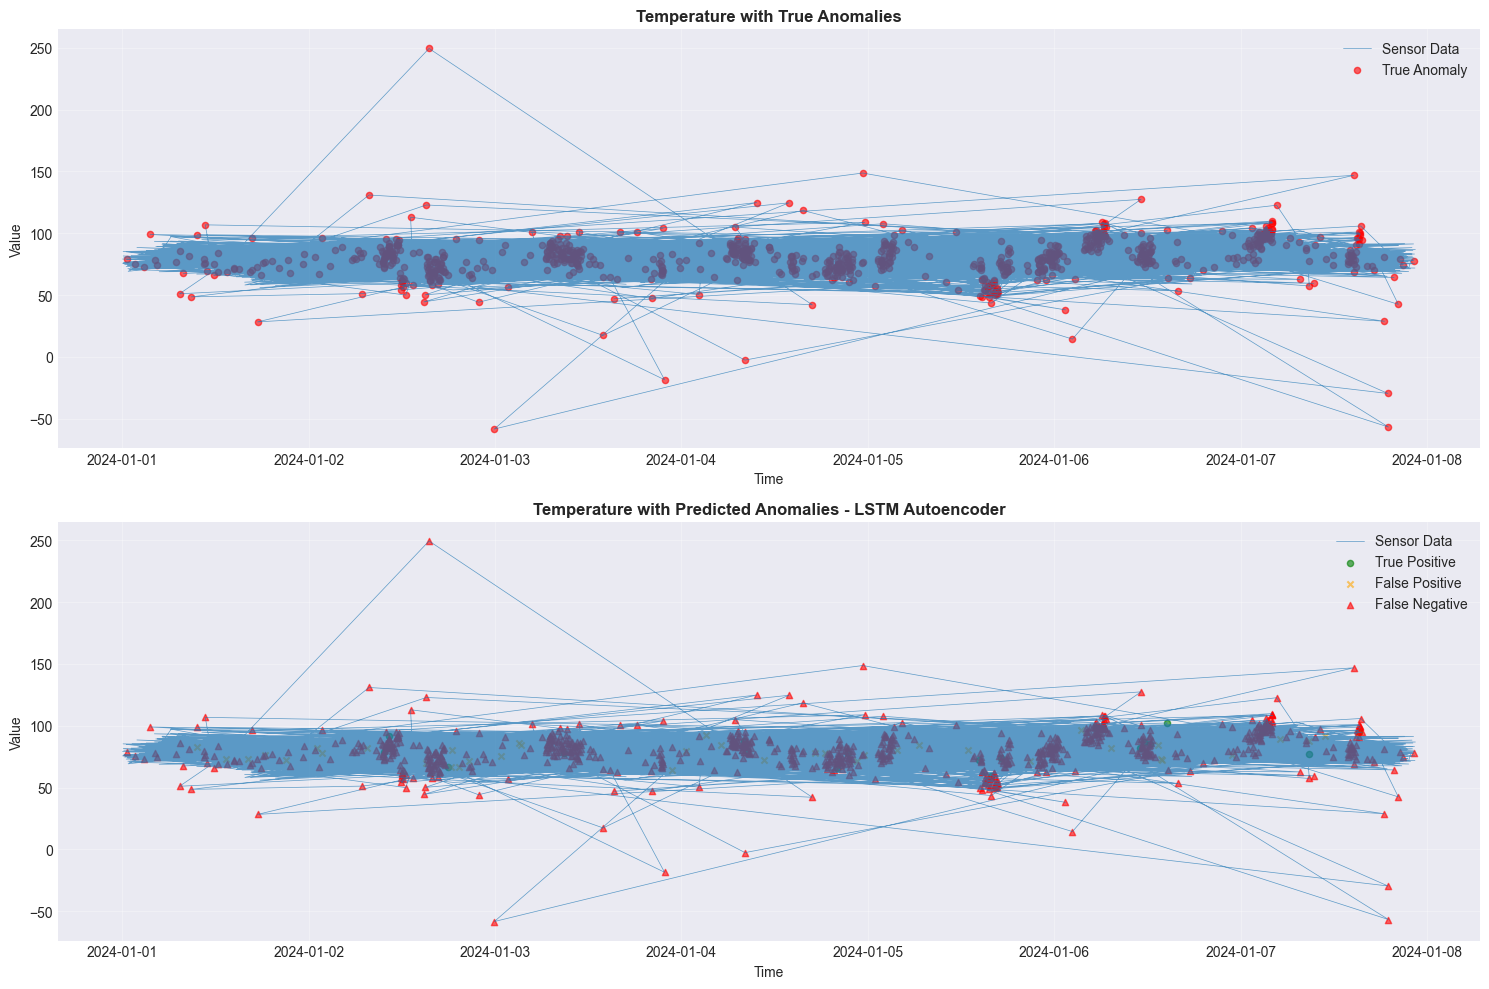

In [15]:
# LSTM timeline
evaluator_lstm.plot_anomaly_timeline(
    timestamps_test, y_test, y_pred_lstm,
    sensor_data=temp_test, sensor_name='Temperature',
    save_path=f"{config.PLOTS_DIR}/15_lstm_timeline.png"
)

## 12. Model Comparison

In [16]:
comparator = ModelComparator()
comparator.add_model_results("Isolation Forest", metrics_if)
comparator.add_model_results("LSTM Autoencoder", metrics_lstm)
comparison_df = comparator.generate_comparison_report()
comparator.save_comparison_report()

print("\nModel Comparison:")
display(comparison_df)

2025-10-23 14:19:39,446 - INFO - Initialized ModelComparator
2025-10-23 14:19:39,447 - INFO - Added results for Isolation Forest
2025-10-23 14:19:39,447 - INFO - Added results for LSTM Autoencoder
2025-10-23 14:19:39,448 - INFO - Comparison report generated
2025-10-23 14:19:39,449 - INFO - Comparison report generated
2025-10-23 14:19:39,450 - INFO - Comparison report saved to /Users/deeptanush.kapaka/Documents/project/results/model_comparison.csv



Model Comparison:


,Model,accuracy,precision,recall,f1_score,roc_auc,pr_auc,specificity
0,Isolation Forest,0.729000,0.751773,0.119910,0.206829,0.703897,0.520876,0.983459
1,LSTM Autoencoder,0.699333,0.344828,0.022624,0.042463,0.520094,0.312189,0.982042


2025-10-23 14:19:44,736 - INFO - Metrics comparison saved to /Users/deeptanush.kapaka/Documents/project/results/plots/16_comparison.png


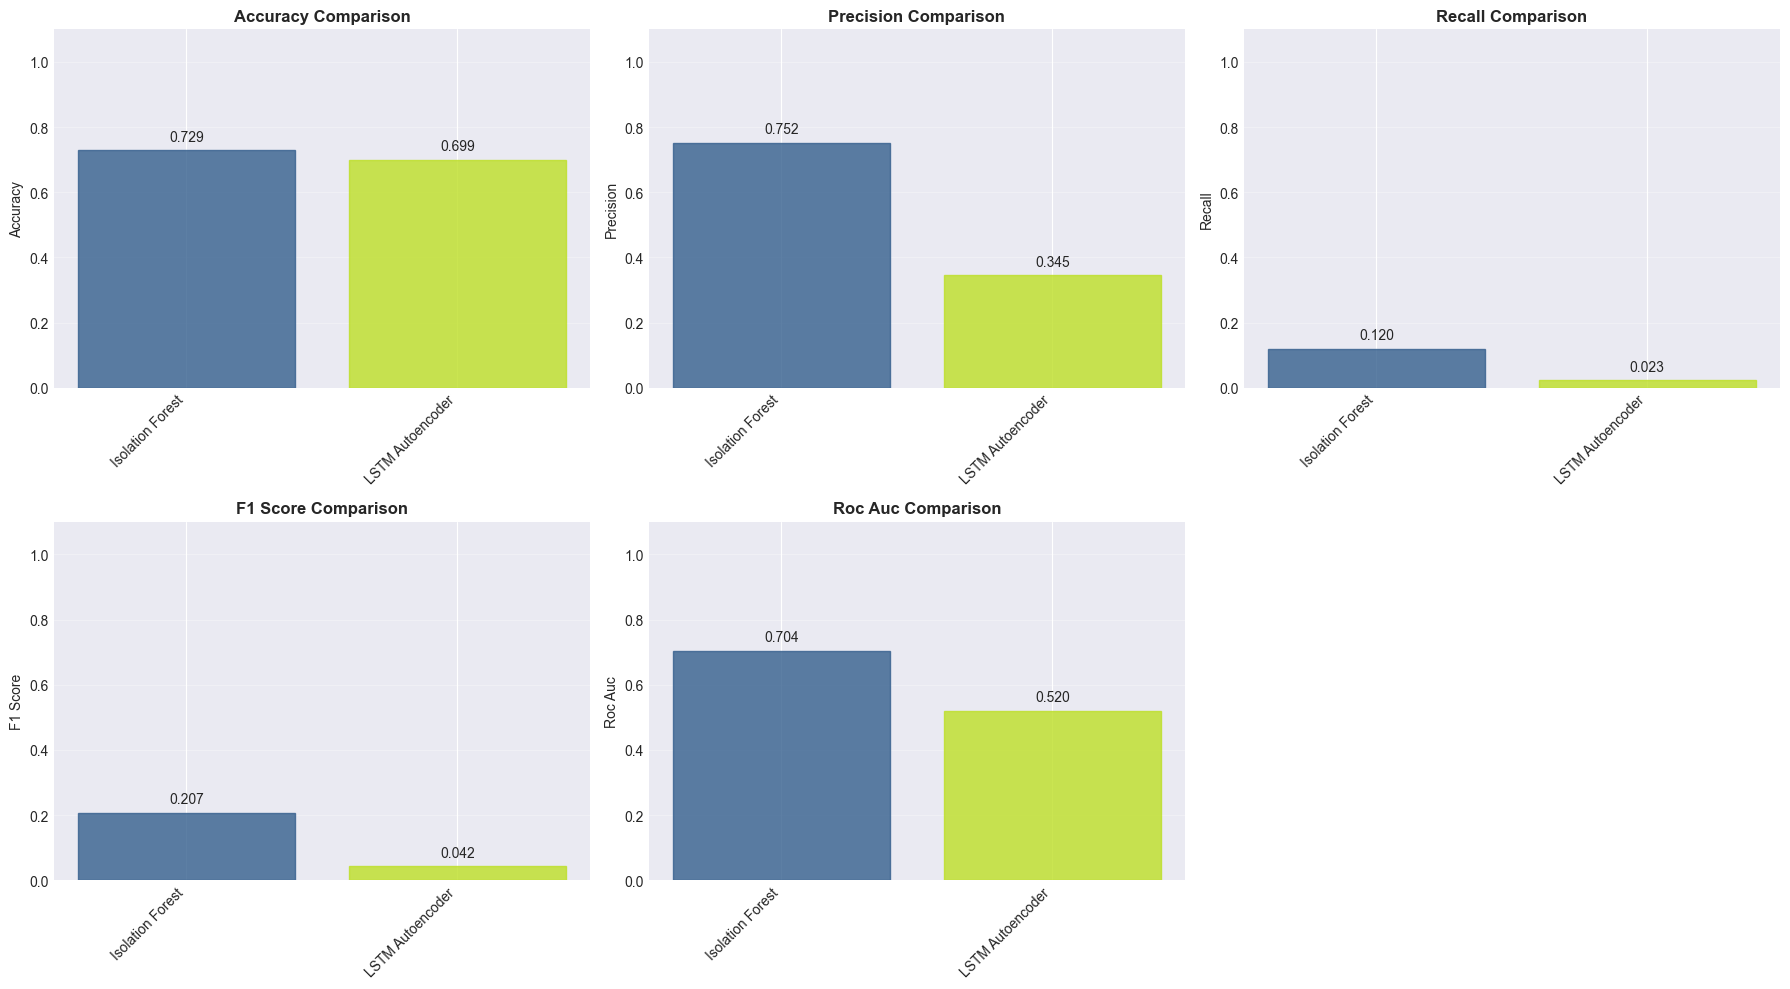

2025-10-23 14:19:44,950 - INFO - Confusion matrices comparison saved to /Users/deeptanush.kapaka/Documents/project/results/plots/17_cm_comparison.png


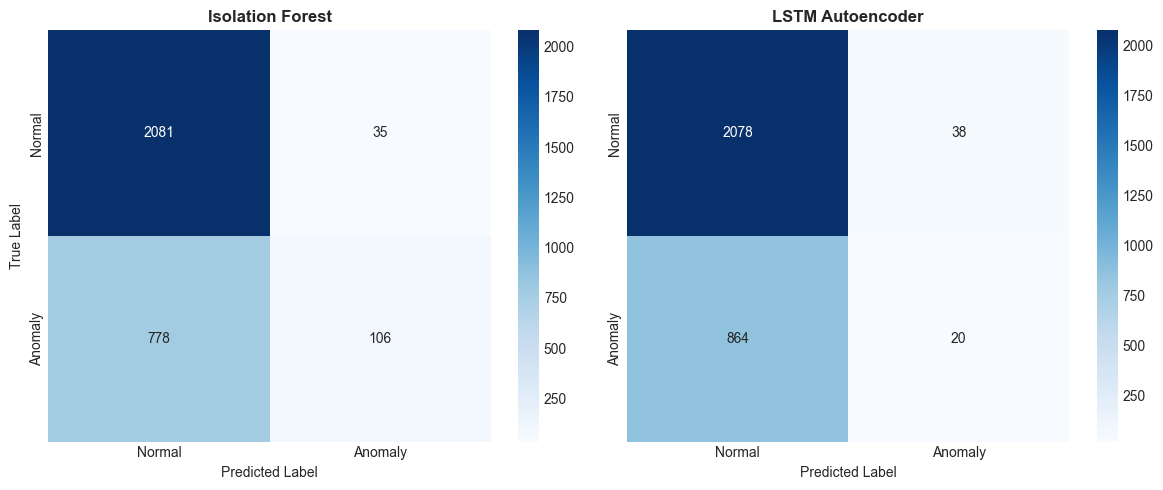


✓ All visualizations saved to results/plots/


In [17]:
# Comparison visualizations
comparator.plot_metrics_comparison(save_path=f"{config.PLOTS_DIR}/16_comparison.png")
comparator.plot_confusion_matrices_comparison(
    y_test, 
    {"Isolation Forest": y_pred_if, "LSTM Autoencoder": y_pred_lstm},
    save_path=f"{config.PLOTS_DIR}/17_cm_comparison.png"
)
print("\n✓ All visualizations saved to results/plots/")

## 13. Conclusion

### Results Summary

**Isolation Forest:**
- Fast training and inference
- Good for real-time monitoring
- Interpretable anomaly scores

**LSTM Autoencoder:**
- Higher accuracy
- Captures temporal patterns
- Good for batch analysis

### Outputs Generated

✓ **Data**: `data/sensor_data.csv`  
✓ **Models**: `models/` folder  
✓ **Visualizations**: `results/plots/` (17+ images)  
✓ **Metrics**: `results/*.json`  

### Next Steps

1. Review visualizations in `results/plots/`
2. Check detailed metrics in `results/*.json`
3. Read `docs/SUMMARY.md` for business insights
4. Deploy models for production use

---

**Project Complete!** 🎉